# Old - Deconvolve

1. Calculating Geometry (Laser: 4.0µm, Step: 2.0µm)...
2. Simulating Raster Scan for Pass Map...


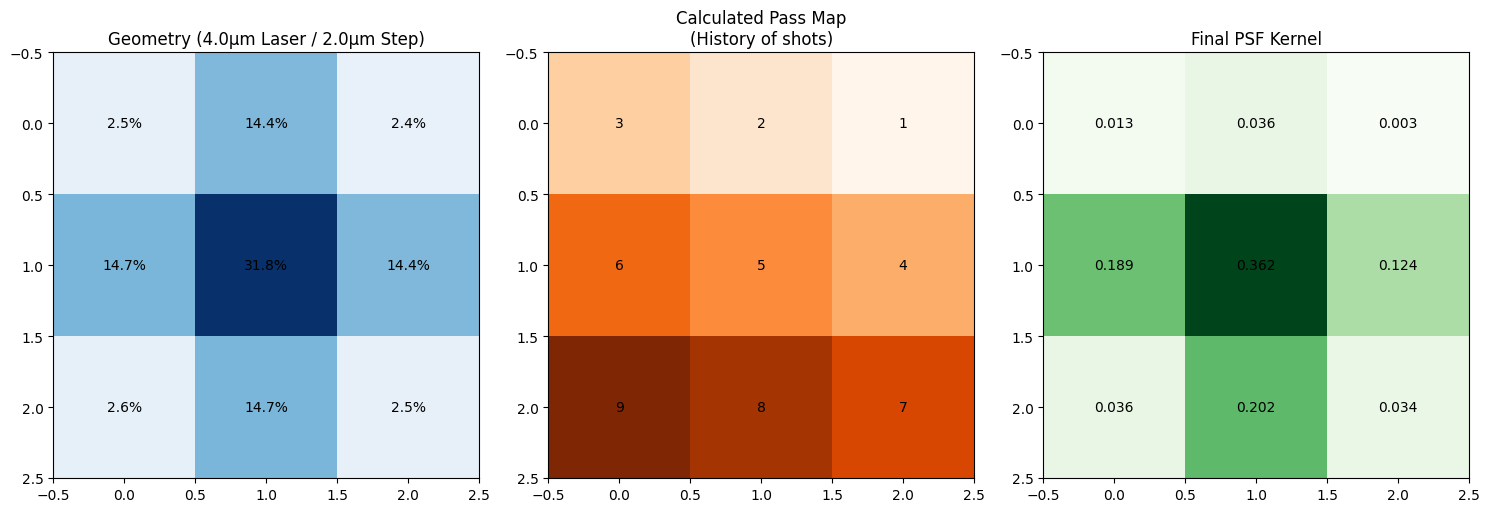


--- YOUR CUSTOM PSF KERNEL ---
[[0.01321213 0.03647785 0.0025337 ]
 [0.18876252 0.36216739 0.1244671 ]
 [0.03639693 0.20201293 0.03396946]]


In [9]:
import numpy as np
import matplotlib.pyplot as plt


def calculate_dynamic_hr_imc_psf(
    laser_diameter_um=4.0, step_size_um=2.0, x0_inflection=5.0
):
    """
    Calculates HR-IMC PSF with DYNAMIC pass map generation.
    Adapts to any laser/step size ratio.
    """

    # --- 1. CONFIGURATION ---
    # A 3x3 kernel is standard for deconvolution
    kernel_size = 3

    # High-resolution simulation grid (20nm per pixel for precision)
    sim_res = 0.02
    # Determine simulation span (must cover the laser reach + kernel area)
    span = (kernel_size * step_size_um) + laser_diameter_um

    # Create coordinate grids
    x = np.arange(-span, span, sim_res)
    y = np.arange(-span, span, sim_res)
    xv, yv = np.meshgrid(x, y)

    laser_radius = laser_diameter_um / 2

    # --- 2. CALCULATE GEOMETRIC OVERLAP MATRIX ---
    geometric_matrix = np.zeros((kernel_size, kernel_size))

    print(
        f"1. Calculating Geometry (Laser: {laser_diameter_um}µm, Step: {step_size_um}µm)..."
    )

    # Laser mask at the current position (Center of kernel, 0,0)
    current_laser_mask = (xv**2 + yv**2) <= laser_radius**2
    total_laser_pixels = np.sum(current_laser_mask)

    for row in range(kernel_size):
        for col in range(kernel_size):
            # Calculate shift relative to center (0,0)
            # Row 0 is Top (y positive shift), Row 2 is Bottom (y negative shift)
            # Col 0 is Left (x negative shift), Col 2 is Right (x positive shift)
            y_center = (1 - row) * step_size_um
            x_center = (col - 1) * step_size_um

            # Create mask for this subpixel square
            y_lower = y_center - (step_size_um / 2)
            y_upper = y_center + (step_size_um / 2)
            x_lower = x_center - (step_size_um / 2)
            x_upper = x_center + (step_size_um / 2)

            subpixel_mask = (
                (xv >= x_lower) & (xv < x_upper) & (yv >= y_lower) & (yv < y_upper)
            )

            # Intersection: How much of the laser is in this pixel?
            overlap = current_laser_mask & subpixel_mask
            geometric_matrix[row, col] = np.sum(overlap)

    # Normalize geometry
    geometric_matrix_norm = geometric_matrix / total_laser_pixels

    # --- 3. DYNAMIC PASS MAP CALCULATION ---
    # This simulates the raster scan history to find "n" (pass number) for each pixel.
    pass_map = np.zeros((kernel_size, kernel_size), dtype=int)

    print("2. Simulating Raster Scan for Pass Map...")

    # We need to check "past" shots.
    # Raster direction: Left->Right, Top->Bottom.
    # We check a grid of potential previous shots relative to the current center.
    # Influence range: ceiling of diameter/step
    search_range = int(np.ceil(laser_diameter_um / step_size_um)) + 2

    for row in range(kernel_size):
        for col in range(kernel_size):
            # Define the specific piece of tissue (Subpixel) we are analyzing
            sub_y = (1 - row) * step_size_um
            sub_x = (col - 1) * step_size_um

            # Define that tissue area mask
            y_lower = sub_y - (step_size_um / 2)
            y_upper = sub_y + (step_size_um / 2)
            x_lower = sub_x - (step_size_um / 2)
            x_upper = sub_x + (step_size_um / 2)
            target_tissue_mask = (
                (xv >= x_lower) & (xv < x_upper) & (yv >= y_lower) & (yv < y_upper)
            )

            pass_count = 0

            # Iterate through PAST laser shots (and current one)
            # Previous rows (y_scan < 0)
            # Current row, previous pixels (y_scan == 0, x_scan <= 0)

            # Check previous rows (from -search_range up to -1)
            for r_scan in range(-search_range, 0):  # Previous rows
                for c_scan in range(
                    -search_range, search_range + 1
                ):  # Any X in previous row
                    shot_y = r_scan * step_size_um
                    shot_x = c_scan * step_size_um

                    # Does this OLD shot hit our TARGET tissue?
                    dist_sq = (xv - shot_x) ** 2 + (yv - shot_y) ** 2
                    shot_mask = dist_sq <= laser_radius**2

                    if np.any(shot_mask & target_tissue_mask):
                        pass_count += 1

            # Check current row (from -search_range up to 0)
            for c_scan in range(
                -search_range, 1
            ):  # Left neighbors and Current Center (0)
                shot_y = 0
                shot_x = c_scan * step_size_um

                dist_sq = (xv - shot_x) ** 2 + (yv - shot_y) ** 2
                shot_mask = dist_sq <= laser_radius**2

                if np.any(shot_mask & target_tissue_mask):
                    pass_count += 1

            pass_map[row, col] = pass_count

    # --- 4. APPLY SIGNAL DECAY ---
    # I0 / (1 + exp(-(x - x0)))
    # Note: We use 1.0 as I0 for the relative factor
    signal_decay_matrix = 1.0 / (1.0 + np.exp(-(pass_map - x0_inflection)))

    # --- 5. FINAL PSF ---
    final_psf = geometric_matrix_norm * signal_decay_matrix
    final_psf /= np.sum(final_psf)  # Normalize

    return geometric_matrix_norm, pass_map, final_psf


# ==========================================
# ENTER YOUR PARAMETERS HERE
# ==========================================
LASER_DIAMETER = 4.0  # µm
STEP_SIZE = 2.0  # µm
X0_VALUE = 3.5  # Hypothetical decay inflection.
# Note: With fewer overlaps, x0 usually needs to be lower
# unless you use very low energy.

geo, passes, psf = calculate_dynamic_hr_imc_psf(LASER_DIAMETER, STEP_SIZE, X0_VALUE)

# --- PLOTTING ---
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Plot 1: Geometry
im1 = axes[0].imshow(geo, cmap="Blues", vmin=0)
axes[0].set_title(f"Geometry ({LASER_DIAMETER}µm Laser / {STEP_SIZE}µm Step)")
for (j, i), label in np.ndenumerate(geo):
    axes[0].text(i, j, f"{label:.1%}", ha="center", va="center", color="black")

# Plot 2: Pass Map
im2 = axes[1].imshow(passes, cmap="Oranges")
axes[1].set_title("Calculated Pass Map\n(History of shots)")
for (j, i), label in np.ndenumerate(passes):
    axes[1].text(i, j, f"{label}", ha="center", va="center", color="black")

# Plot 3: Final PSF
im3 = axes[2].imshow(psf, cmap="Greens")
axes[2].set_title("Final PSF Kernel")
for (j, i), label in np.ndenumerate(psf):
    axes[2].text(i, j, f"{label:.3f}", ha="center", va="center", color="black")

plt.tight_layout()
plt.show()

print("\n--- YOUR CUSTOM PSF KERNEL ---")
print(psf)

In [ ]:
import tifffile
import os
from pathlib import Path
from skimage.restoration import richardson_lucy

# Read TIFF files from the directory
INPUT_DIR = "/mnt/eternus/users/Davide/maldi-deconv-rl/data/Sven_Chiahsin_Deconvolution_Oversampling_MALDI/Oversampled/new_tiffs_single_ions"
OUTPUT_DIR = "/mnt/eternus/users/Davide/maldi-deconv-rl/output/new_psf/2"
Path(OUTPUT_DIR).mkdir(parents=True, exist_ok=True)

tiff_files = sorted(
    [f for f in os.listdir(INPUT_DIR) if f.endswith(".tif") or f.endswith(".tiff")]
)

# Load and process each TIFF file
images = {}
for filename in tiff_files:
    filepath = os.path.join(INPUT_DIR, filename)
    img = tifffile.imread(filepath)

    # Sum all channels if RGB (last dimension is 3)
    if len(img.shape) == 3 and img.shape[-1] == 3:
        img = np.sum(img, axis=2)

    # Normalize to [0, 1]
    img = img.astype(float)
    img = img / np.max(img) if np.max(img) > 0 else img

    images[filename] = img

print(f"Loaded {len(images)} images")

# Apply RL deconvolution to all images and save each iteration in multi-page TIFF
num_iterations = 10

for filename, img in images.items():
    print(f"\nProcessing {filename}...")
    base_name = os.path.splitext(filename)[0]

    # Collect all iterations in a list
    iterations_stack = []

    # Add original normalized image as iteration 0
    iterations_stack.append(img.astype(np.float32))

    # Perform RL deconvolution with iterative collection
    estimate = img.copy()
    for iteration in range(1, num_iterations + 1):
        estimate = richardson_lucy(estimate, psf, num_iter=1)
        iterations_stack.append(estimate.astype(np.float32))
        print(f"  Completed iteration {iteration}")

    # Save all iterations as multi-page TIFF
    output_path = os.path.join(OUTPUT_DIR, f"{base_name}_all_iterations_new.tif")
    tifffile.imwrite(output_path, np.array(iterations_stack), photometric="minisblack")
    print(f"  ✓ Saved {len(iterations_stack)} iterations to multi-page TIFF")

print(f"\n✓ Processed {len(images)} images with {num_iterations} RL iterations each")
print(f"✓ Results saved to: {OUTPUT_DIR}")

# Convolve

In [ ]:
import tifffile
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.ndimage import convolve

# Load the 2µm step image
img_path = "/mnt/eternus/users/Davide/maldi-deconv-rl/data/Sven_Chiahsin_Deconvolution_Oversampling_MALDI/Oversampled/tiffs_single_ions/A43-5_834.601122u-(834.610000-834.600000) exported.tif"
img = tifffile.imread(img_path)

# Sum RGB channels if needed
if len(img.shape) == 3 and img.shape[-1] == 3:
    img = np.sum(img, axis=2)

# Normalize
img = img.astype(float)
img = img / np.max(img) if np.max(img) > 0 else img

print(f"Original image shape (2µm steps): {img.shape}")

# Generate PSF for 4µm steps (laser still 4µm diameter)
geo_4um, passes_4um, psf_4um = calculate_dynamic_hr_imc_psf(
    laser_diameter_um=4.0,
    step_size_um=2,  # Changed to 4µm steps
    x0_inflection=3.5,
)

print(f"\nPSF for 4µm steps:")
print(psf_4um)

# Step 1: Convolve with 4µm PSF
img_convolved = convolve(img, psf_4um, mode="constant")

# Step 2: Downsample to 4µm steps (every other pixel)
# img_4um = img_convolved[::2, ::2]

img_4um = img_convolved

print(f"\nSimulated image shape (4µm steps): {img_4um.shape}")

# Visualize comparison
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

im1 = axes[0, 0].imshow(img, cmap="viridis")
axes[0, 0].set_title(f"Original: 2µm steps\n{img.shape[0]}×{img.shape[1]} pixels")
plt.colorbar(im1, ax=axes[0, 0])

im2 = axes[0, 1].imshow(psf_4um, cmap="Greens")
axes[0, 1].set_title("PSF for 4µm steps")
for (j, i), label in np.ndenumerate(psf_4um):
    axes[0, 1].text(i, j, f"{label:.3f}", ha="center", va="center", color="black")

im3 = axes[1, 0].imshow(img_convolved, cmap="viridis")
axes[1, 0].set_title(
    f"After convolution\n{img_convolved.shape[0]}×{img_convolved.shape[1]} pixels"
)
plt.colorbar(im3, ax=axes[1, 0])

im4 = axes[1, 1].imshow(img_4um, cmap="viridis")
axes[1, 1].set_title(
    f"Final: Convolved + Downsampled\n{img_4um.shape[0]}×{img_4um.shape[1]} pixels"
)
plt.colorbar(im4, ax=axes[1, 1])

plt.tight_layout()
plt.show()

# Save the simulated 4µm image
OUTPUT_DIR = Path("/mnt/eternus/users/Davide/maldi-deconv-rl/output/convolved")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
output_path = OUTPUT_DIR / "A43-5_834_simulated_4um_steps.tif"
tifffile.imwrite(output_path, img_4um.astype(np.float32))
print(f"\n✓ Saved simulated 4µm image to: {output_path}")

In [ ]:
def create_gaussian_psf(beam_diameter_1e2_um=4.0, step_size_um=2.0, kernel_size=7):
    """
    Creates a Gaussian PSF with 1/e² beam diameter.

    Parameters:
    -----------
    beam_diameter_1e2_um : float
        1/e² beam diameter in micrometers (where intensity drops to 13.5% of peak)
    step_size_um : float
        Pixel size / step size in micrometers
    kernel_size : int
        Size of the PSF kernel (must be odd)

    Returns:
    --------
    psf : numpy.ndarray
        Normalized Gaussian PSF kernel
    """
    # For Gaussian beam: w₀ (1/e² radius) = diameter/2
    w0 = beam_diameter_1e2_um / 2.0  # in micrometers

    # Convert to pixel units
    w0_pixels = w0 / step_size_um

    # Create coordinate grid centered at 0
    center = kernel_size // 2
    x = np.arange(kernel_size) - center
    y = np.arange(kernel_size) - center
    xv, yv = np.meshgrid(x, y)

    # Gaussian intensity profile: I(r) = I₀ * exp(-2r²/w₀²)
    # The factor of 2 comes from the 1/e² definition
    r_squared = xv**2 + yv**2
    psf = np.exp(-2 * r_squared / (w0_pixels**2))

    # Normalize so sum = 1
    psf = psf / np.sum(psf)

    return psf


# Generate Gaussian PSF
psf_gaussian = create_gaussian_psf(
    beam_diameter_1e2_um=4.0,
    step_size_um=2,
    kernel_size=3,  # 7x7 kernel to capture the Gaussian tails
)

# Visualize
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# 2D heatmap
im1 = axes[0].imshow(psf_gaussian, cmap="hot", interpolation="nearest")
axes[0].set_title("Gaussian PSF (1/e² width = 4μm)\n7×7 kernel")
plt.colorbar(im1, ax=axes[0])

# Add values to cells
for (j, i), val in np.ndenumerate(psf_gaussian):
    axes[0].text(
        i,
        j,
        f"{val:.4f}",
        ha="center",
        va="center",
        color="white" if val > 0.3 else "black",
        fontsize=8,
    )

# Cross-section profile
center = psf_gaussian.shape[0] // 2
profile = psf_gaussian[center, :]
x_um = (np.arange(len(profile)) - center) * 2.0  # Convert to micrometers

axes[1].plot(x_um, profile, "o-", linewidth=2)
axes[1].axhline(y=np.exp(-2), color="r", linestyle="--", label="1/e² level (13.5%)")
axes[1].axvline(x=2.0, color="gray", linestyle=":", alpha=0.5)
axes[1].axvline(x=-2.0, color="gray", linestyle=":", alpha=0.5)
axes[1].set_xlabel("Distance from center (μm)")
axes[1].set_ylabel("Normalized intensity")
axes[1].set_title("Gaussian Profile (horizontal slice)")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

print("Gaussian PSF kernel:")
print(psf_gaussian)
print(f"\nPSF sum: {psf_gaussian.sum():.6f} (should be 1.0)")

In [ ]:
psf = psf_gaussian


import tifffile
import os
from pathlib import Path
from skimage.restoration import richardson_lucy

# Read TIFF files from the directory
INPUT_DIR = "/mnt/eternus/users/Davide/maldi-deconv-rl/data/Sven_Chiahsin_Deconvolution_Oversampling_MALDI/Oversampled/tiffs_single_ions"
OUTPUT_DIR = "/mnt/eternus/users/Davide/maldi-deconv-rl/output/new_psf"
Path(OUTPUT_DIR).mkdir(parents=True, exist_ok=True)

tiff_files = sorted(
    [f for f in os.listdir(INPUT_DIR) if f.endswith(".tif") or f.endswith(".tiff")]
)

# Load and process each TIFF file
images = {}
for filename in tiff_files:
    filepath = os.path.join(INPUT_DIR, filename)
    img = tifffile.imread(filepath)

    # Sum all channels if RGB (last dimension is 3)
    if len(img.shape) == 3 and img.shape[-1] == 3:
        img = np.sum(img, axis=2)

    # Normalize to [0, 1]
    img = img.astype(float)
    img = img / np.max(img) if np.max(img) > 0 else img

    images[filename] = img

print(f"Loaded {len(images)} images")

# Apply RL deconvolution to all images and save each iteration in multi-page TIFF
num_iterations = 10

for filename, img in images.items():
    print(f"\nProcessing {filename}...")
    base_name = os.path.splitext(filename)[0]

    # Collect all iterations in a list
    iterations_stack = []

    # Add original normalized image as iteration 0
    iterations_stack.append(img.astype(np.float32))

    # Perform RL deconvolution with iterative collection
    estimate = img.copy()
    for iteration in range(1, num_iterations + 1):
        estimate = richardson_lucy(estimate, psf, num_iter=1)
        iterations_stack.append(estimate.astype(np.float32))
        print(f"  Completed iteration {iteration}")

    # Save all iterations as multi-page TIFF
    output_path = os.path.join(OUTPUT_DIR, f"{base_name}_all_iterations_new.tif")
    tifffile.imwrite(output_path, np.array(iterations_stack), photometric="minisblack")
    print(f"  ✓ Saved {len(iterations_stack)} iterations to multi-page TIFF")

print(f"\n✓ Processed {len(images)} images with {num_iterations} RL iterations each")
print(f"✓ Results saved to: {OUTPUT_DIR}")

In [ ]:
from pyimzml.ImzMLParser import ImzMLParser

p = ImzMLParser(
    "data/Sven_Chiahsin_Deconvolution_Oversampling_MALDI/Oversampled/QEHF1_CC243-16_MouseCerebellum_DHAP_2um_A42_225x225.imzml"
)

In [ ]:
p.intensityLengths

# NEW - Deconvolve

In [14]:
LASER_DIAMETER = 4.0  # µm
STEP_SIZE = 1.3  # µm
KERNEL_SIZE = 3 # px 

DECAY_CSV_PATH = "/mnt/eternus/users/Davide/maldi-deconv-rl/data/Sven_Chiahsin_Deconvolution_Oversampling_MALDI/Signal loss/DHAP_positive ion mode/A43.5.csv"
INPUT_DIR = "/mnt/eternus/users/Davide/maldi-deconv-rl/data/Sven_Chiahsin_Deconvolution_Oversampling_MALDI/Tumor/260-2_Tumor_1.3 µm/extracted_tiffs"
OUTPUT_DIR = "/mnt/eternus/users/Davide/maldi-deconv-rl/data/Sven_Chiahsin_Deconvolution_Oversampling_MALDI/Tumor/260-2_Tumor_1.3 µm/deconvolved_tiffs"

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import tifffile
from skimage.restoration import richardson_lucy
from pathlib import Path

# --- 1. Load Decay Data from CSV ---
if os.path.exists(DECAY_CSV_PATH):
    decay_df = pd.read_csv(DECAY_CSV_PATH)
    # Normalize intensity relative to the first pass
    decay_df["normalized_intensity"] = (
        decay_df["Average intensity"] / decay_df["Average intensity"].iloc[0]
    )

    # Create a lookup dictionary
    decay_lookup = dict(
        zip(decay_df["Number of passes"], decay_df["normalized_intensity"])
    )
    # Get the last valid decay value for clamping (no extrapolation)
    max_passes_in_data = decay_df["Number of passes"].max()
    last_decay_value = decay_df.loc[
        decay_df["Number of passes"] == max_passes_in_data, "normalized_intensity"
    ].values[0]

    print("Loaded Signal Decay Data:")
    print(decay_df[["Number of passes", "normalized_intensity"]].head(10))
else:
    print(f"Warning: CSV file not found at {DECAY_CSV_PATH}. Using identity decay.")
    decay_lookup = {1: 1.0}
    max_passes_in_data = 1
    last_decay_value = 1.0


def get_decay_factor(n_passes):
    # Retrieve decay factor. If n_passes > data, clamp to last known value.
    if n_passes < 1:
        return 1.0
    if n_passes > max_passes_in_data:
        return last_decay_value
    return decay_lookup.get(int(n_passes), last_decay_value)


v_get_decay = np.vectorize(get_decay_factor)


# --- 2. Define New Integrated Gaussian + Decay PSF Function ---
def create_decay_compensated_gaussian_psf(
    beam_diameter_um=4.0, step_size_um=2.0, kernel_size=3
):
    """
    Creates a PSF that combines an **Integrated** Gaussian beam profile with intensity decay.
    Changes from previous:
    1. Uses fine-grid integration for the Gaussian part (like the geometric calculation),
       not just center-point sampling.
    2. Applies decay based on user CSV.
    """
    print(
        f"\nGenerating PSF (Integrated Gaussian + Decay): Beam {beam_diameter_um}um, Step {step_size_um}um"
    )

    # Simulation Grid (Fine resolution)
    sim_res = 0.02
    span = (kernel_size * step_size_um) + beam_diameter_um
    sim_x = np.arange(-span, span, sim_res)
    sim_y = np.arange(-span, span, sim_res)
    xv_sim, yv_sim = np.meshgrid(sim_x, sim_y)

    center_idx = kernel_size // 2

    # 1. Define Gaussian Intensity Field on the High-Res Grid
    w0 = beam_diameter_um / 2.0  # 1/e^2 beam radius
    r_squared_sim = xv_sim**2 + yv_sim**2
    # Gaussian Profile I(r)
    gaussian_field_sim = np.exp(-2 * r_squared_sim / (w0**2))

    # 2. Logic Containers
    gaussian_integrated_matrix = np.zeros((kernel_size, kernel_size))
    pass_map = np.zeros((kernel_size, kernel_size), dtype=int)

    # Calc total theoretical energy for normalization
    total_gaussian_energy = np.sum(gaussian_field_sim)

    # Raster Simulation Params
    laser_radius = beam_diameter_um / 2
    search_range = int(np.ceil(beam_diameter_um / step_size_um)) + 2

    for row in range(kernel_size):
        for col in range(kernel_size):
            # Coordinates of this pixel's center relative to kernel center (0,0)
            # Row 0 (Top) -> positive y shift
            y_center = (1 - row) * step_size_um
            # Col 0 (Left) -> negative x shift
            x_center = (col - 1) * step_size_um

            # Pixel boundary mask
            y_lower = y_center - (step_size_um / 2)
            y_upper = y_center + (step_size_um / 2)
            x_lower = x_center - (step_size_um / 2)
            x_upper = x_center + (step_size_um / 2)

            pixel_mask = (
                (xv_sim >= x_lower)
                & (xv_sim < x_upper)
                & (yv_sim >= y_lower)
                & (yv_sim < y_upper)
            )

            # A. Spatial Component: Integrate Gaussian Intensity under this pixel
            # This is "How much laser power tends to fall here"
            gaussian_integrated_matrix[row, col] = np.sum(
                gaussian_field_sim[pixel_mask]
            )

            # B. Temporal Component: Pass Map (Re-using logic)
            pass_count = 0

            # Check Past Shots
            # 1. Previous Rows
            for r_scan in range(-search_range, 0):
                for c_scan in range(-search_range, search_range + 1):
                    shot_y = r_scan * step_size_um
                    shot_x = c_scan * step_size_um
                    dist_sq = (xv_sim - shot_x) ** 2 + (yv_sim - shot_y) ** 2
                    if np.any((dist_sq <= laser_radius**2) & pixel_mask):
                        pass_count += 1

            # 2. Current Row (Past columns + Current)
            for c_scan in range(-search_range, 1):
                shot_y = 0
                shot_x = c_scan * step_size_um
                dist_sq = (xv_sim - shot_x) ** 2 + (yv_sim - shot_y) ** 2
                if np.any((dist_sq <= laser_radius**2) & pixel_mask):
                    pass_count += 1

            pass_map[row, col] = pass_count

    # Normalize Spatial Component (Fraction of total beam energy)
    # Using sum of matrix ensures it sums to 1 naturally for the spatial part
    gaussian_norm = gaussian_integrated_matrix / np.sum(gaussian_integrated_matrix)

    # C. Decay Factors
    decay_factors = v_get_decay(pass_map)

    # D. Final Combination
    final_psf = gaussian_norm * decay_factors
    final_psf /= np.sum(final_psf)  # Re-normalize final

    return gaussian_norm, pass_map, final_psf


Loaded Signal Decay Data:
   Number of passes  normalized_intensity
0                 1              1.000000
1                 2              0.882740
2                 3              0.688459
3                 4              0.557712
4                 5              0.485149
5                 6              0.420046
6                 7              0.355511
7                 8              0.303648
8                 9              0.251022
9                10              0.237529



Generating PSF (Integrated Gaussian + Decay): Beam 4.0um, Step 1.3um

--- Comparing with Original Geometric PSF ---
1. Calculating Geometry (Laser: 4.0µm, Step: 1.3µm)...
2. Simulating Raster Scan for Pass Map...


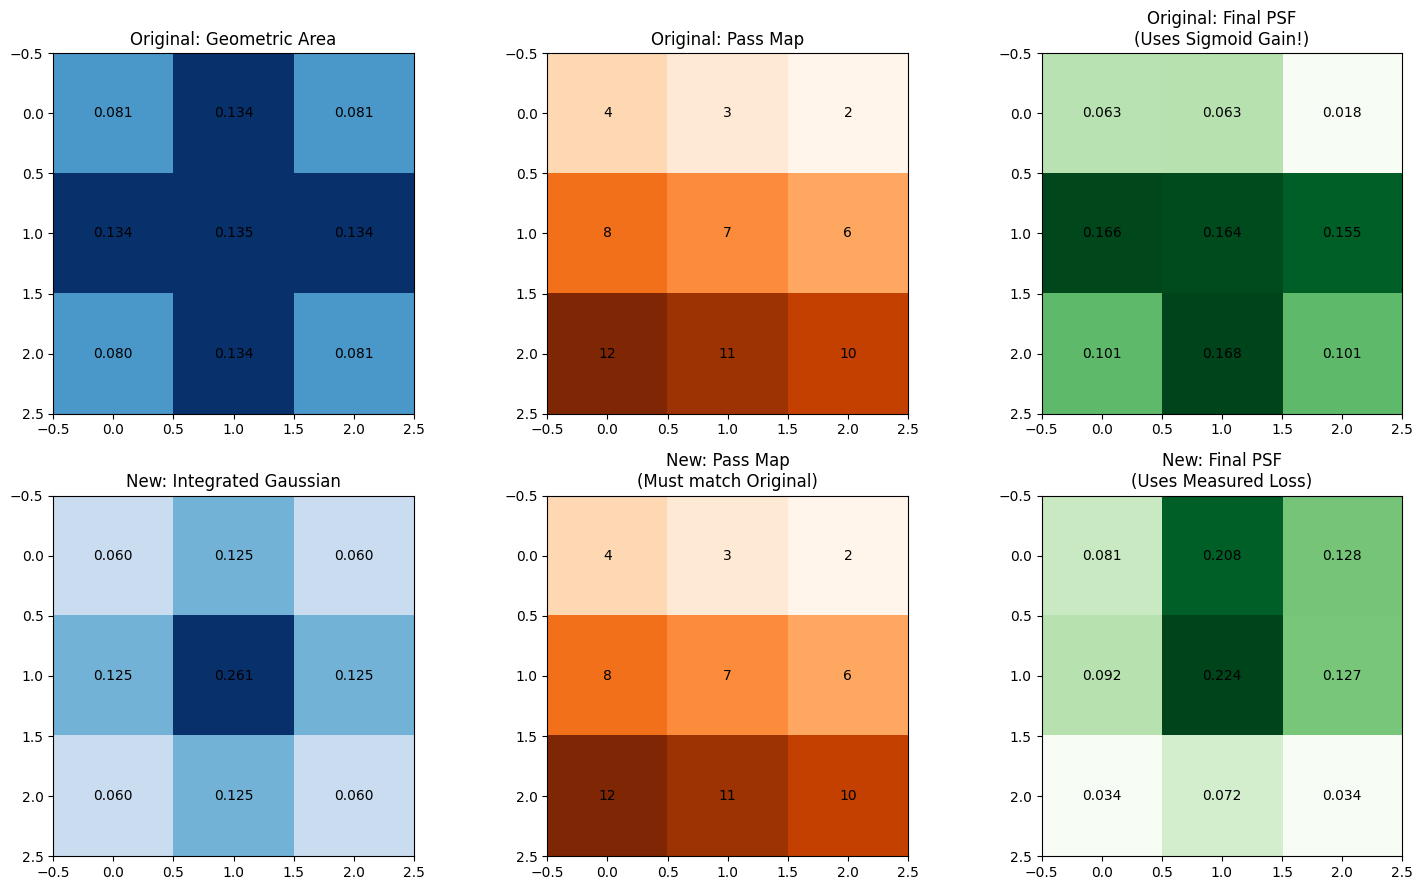


Observation:
- The Pass Maps should be identical.
- The 'Geometric Area' vs 'Integrated Gaussian' show subtle shape differences (Gaussian is 'softer').
- The Final PSFs are VERY different because the original logical used a Sigmoid function that INCREASED signal with passes, whereas your CSV data shows signal LOSS.
psf_old [[0.0629865  0.0634053  0.01845959]
 [0.16601868 0.1640296  0.15520312]
 [0.10108918 0.16777019 0.10103784]]
psf_new [[0.08081153 0.2080182  0.12790755]
 [0.09174724 0.22399404 0.12691695]
 [0.03441753 0.07176943 0.03441753]]
pass map [[ 4  3  2]
 [ 8  7  6]
 [12 11 10]]


In [18]:


# --- Generate New PSF ---
geo_gauss, passes_new, psf_new = create_decay_compensated_gaussian_psf(LASER_DIAMETER, STEP_SIZE, KERNEL_SIZE)

# --- Retrieve Old PSF (for comparison) ---
# Assuming calculate_dynamic_hr_imc_psf is defined in the notebook context
try:
    print("\n--- Comparing with Original Geometric PSF ---")
    geo_old, passes_old, psf_old = calculate_dynamic_hr_imc_psf(
        laser_diameter_um=LASER_DIAMETER,
        step_size_um=STEP_SIZE,
        x0_inflection=3.5,  # As used previously
    )
except NameError:
    print("calculate_dynamic_hr_imc_psf not found in memory. Skipping comparison.")
    geo_old, passes_old, psf_old = np.zeros((3, 3)), np.zeros((3, 3)), np.zeros((3, 3))

# --- Visualization Comparison ---
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

# Row 1: Original Geometric
im1 = axes[0, 0].imshow(geo_old, cmap="Blues", vmin=0)
axes[0, 0].set_title("Original: Geometric Area")
for (j, i), val in np.ndenumerate(geo_old):
    axes[0, 0].text(i, j, f"{val:.3f}", ha="center", va="center")

im2 = axes[0, 1].imshow(passes_old, cmap="Oranges")
axes[0, 1].set_title("Original: Pass Map")
for (j, i), val in np.ndenumerate(passes_old):
    axes[0, 1].text(i, j, f"{val}", ha="center", va="center")

im3 = axes[0, 2].imshow(psf_old, cmap="Greens")
axes[0, 2].set_title("Original: Final PSF\n(Uses Sigmoid Gain!)")
for (j, i), val in np.ndenumerate(psf_old):
    axes[0, 2].text(i, j, f"{val:.3f}", ha="center", va="center")

# Row 2: New Gaussian + Decay
im4 = axes[1, 0].imshow(geo_gauss, cmap="Blues", vmin=0)
axes[1, 0].set_title("New: Integrated Gaussian")
for (j, i), val in np.ndenumerate(geo_gauss):
    axes[1, 0].text(
        i,
        j,
        f"{val:.3f}",
        ha="center",
        va="center",
    )

im5 = axes[1, 1].imshow(passes_new, cmap="Oranges")
axes[1, 1].set_title("New: Pass Map\n(Must match Original)")
for (j, i), val in np.ndenumerate(passes_new):
    axes[1, 1].text(i, j, f"{val}", ha="center", va="center")

im6 = axes[1, 2].imshow(psf_new, cmap="Greens")
axes[1, 2].set_title("New: Final PSF\n(Uses Measured Loss)")
for (j, i), val in np.ndenumerate(psf_new):
    axes[1, 2].text(i, j, f"{val:.3f}", ha="center", va="center")

plt.tight_layout()
plt.show()

print("\nObservation:")
print("- The Pass Maps should be identical.")
print(
    "- The 'Geometric Area' vs 'Integrated Gaussian' show subtle shape differences (Gaussian is 'softer')."
)
print(
    "- The Final PSFs are VERY different because the original logical used a Sigmoid function that INCREASED signal with passes, whereas your CSV data shows signal LOSS."
)

print("psf_old", psf_old)
print("psf_new", psf_new)
print("pass map", passes_new)

# NEW WITH CLASS    

Loaded Signal Decay Data:
   Number of passes  Average intensity
0                 1       126872.37310
1                 2       111995.33230
2                 3        87346.44147
3                 4        70758.24519
4                 5        61551.94663
5                 6        53292.18146
6                 7        45104.56331
7                 8        38524.48792
8                 9        31847.70193
9                10        30135.84648
Generating PSF (Method: geometric, Decay Model: exponential): Beam 4.0um, Step 1.3um
Exponential fit successful: a=0.92, b=0.21, c=0.10

--- Gaussian Shape (Spatial Component) ---
[[0.0633822  0.12848819 0.05988783]
 [0.12848819 0.26047083 0.12140441]
 [0.05988783 0.12140441 0.05658611]]

--- Pass Map (Effective Dose) ---
[[6.76331361e+00 5.76627219e+00 5.16272189e+00]
 [4.14201183e+00 3.14053254e+00 2.15532544e+00]
 [1.55325444e+00 5.68047337e-01 1.47928994e-03]]

--- Final PSF (Decay Compensated) ---
[[0.03480418 0.08065605 0.04236611]
 

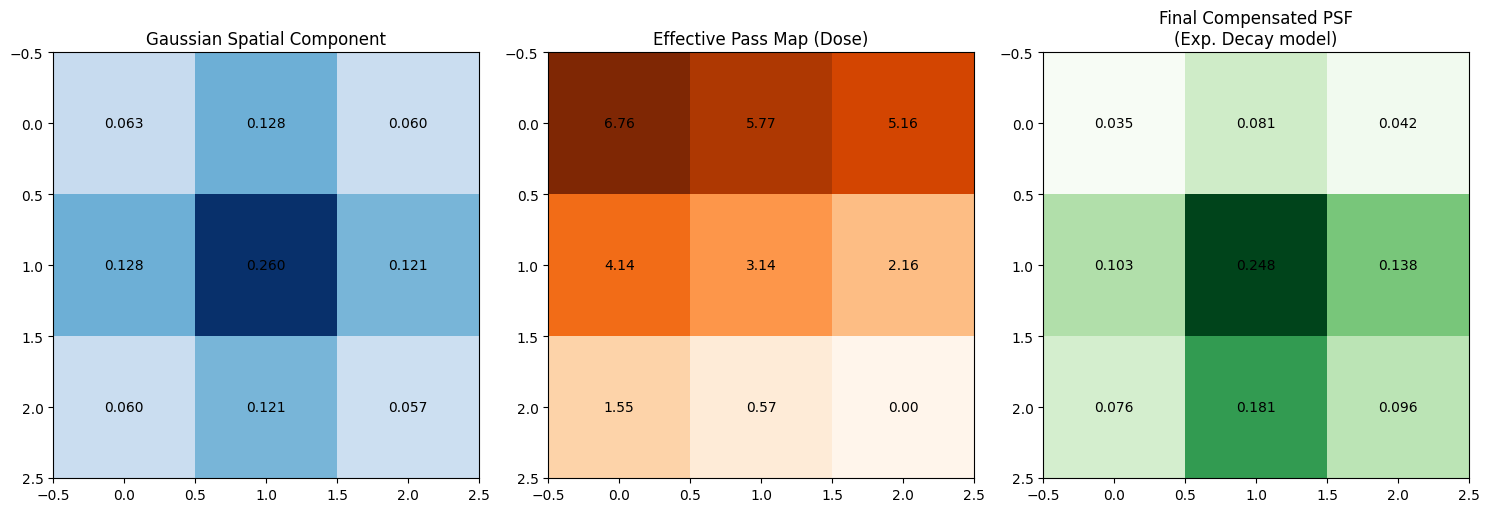

In [19]:
from psf_generator import MaldiPSFGenerator, load_decay_profile
import numpy as np

# Configuration
# LASER_DIAMETER = 4.0   # µm
# STEP_SIZE = 1.3      # µm
# KERNEL_SIZE = 3
# Use the path defined in your notebook
DECAY_CSV_PATH = "/mnt/eternus/users/Davide/maldi-deconv-rl/data/Sven_Chiahsin_Deconvolution_Oversampling_MALDI/Signal loss/DHAP_positive ion mode/A43.5.csv"

# 1. Load data
decay_factors = load_decay_profile(DECAY_CSV_PATH)

# 2. Initialize generator
gen = MaldiPSFGenerator(laser_diameter_um=LASER_DIAMETER, step_size_um=STEP_SIZE)

# 3. Compute PSF with Exponential Decay Fit
# method='beam_profile' calculates the rigorous effective dose
# decay_model='exponential' fits the curve y = a*exp(-b*x) + c
geo, passes, psf = gen.compute_psf(
    kernel_size=KERNEL_SIZE, 
    decay_factors=decay_factors, 
    decay_model='exponential', 
    method='geometric'
)

print("\n--- Gaussian Shape (Spatial Component) ---")
print(geo)

print("\n--- Pass Map (Effective Dose) ---")
print(passes)

print("\n--- Final PSF (Decay Compensated) ---")
print(psf)

print(f"\nPSF Sum: {np.sum(psf)}")

import matplotlib.pyplot as plt

# --- Visualization ---
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Plot 1: Gaussian Shape (Spatial Component)
im1 = axes[0].imshow(geo, cmap="Blues", vmin=0)
axes[0].set_title("Gaussian Spatial Component")
for (j, i), val in np.ndenumerate(geo):
    axes[0].text(i, j, f"{val:.3f}", ha="center", va="center", color="black")

# Plot 2: Pass Map (Effective Dose)
im2 = axes[1].imshow(passes, cmap="Oranges")
axes[1].set_title("Effective Pass Map (Dose)")
for (j, i), val in np.ndenumerate(passes):
    axes[1].text(i, j, f"{val:.2f}", ha="center", va="center", color="black")

# Plot 3: Final PSF (Decay Compensated)
im3 = axes[2].imshow(psf, cmap="Greens")
axes[2].set_title("Final Compensated PSF\n(Exp. Decay model)")
for (j, i), val in np.ndenumerate(psf):
    axes[2].text(i, j, f"{val:.3f}", ha="center", va="center", color="black")

plt.tight_layout()
plt.show()

In [ ]:
# --- 3. Execute Deconvolution ---
# Assuming 'images' variable exists from previous cells

Path(OUTPUT_DIR).mkdir(parents=True, exist_ok=True)

tiff_files = sorted(
    [f for f in os.listdir(INPUT_DIR) if f.endswith(".tif") or f.endswith(".tiff")]
)

# Load and process each TIFF file
images = {}
for filename in tiff_files:
    filepath = os.path.join(INPUT_DIR, filename)
    img = tifffile.imread(filepath)

    # Sum all channels if RGB (last dimension is 3)
    if len(img.shape) == 3 and img.shape[-1] == 3:
        img = np.sum(img, axis=2)

    # Normalize to [0, 1]
    img = img.astype(float)
    img = img / np.max(img) if np.max(img) > 0 else img

    images[filename] = img

print(f"Loaded {len(images)} images")

if "images" in locals():
    print(f"\nProcessing {len(images)} images using the new Gaussian+Decay PSF...")
    num_iterations = 10

    for filename, img in images.items():
        print(f"  Deconvolving \"{filename}\" ...")
        base_name = os.path.splitext(filename)[0]

        iterations_stack = [img.astype(np.float32)]
        estimate = img.copy()

        for iteration in range(1, num_iterations + 1):
            estimate = richardson_lucy(estimate, psf_new, num_iter=1)
            iterations_stack.append(estimate.astype(np.float32))

        out_path = os.path.join(OUTPUT_DIR, f"{base_name}_deconvolved.tif")
        tifffile.imwrite(out_path, np.array(iterations_stack), photometric="minisblack")

    print(f"✓ Saved results to {OUTPUT_DIR}")
else:
    print(
        "\n[NOTE] 'images' variable not found. Please ensure you ran the image loading cell before running this cell."
    )